In [1]:
import sys
import subprocess
import importlib.util

packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn"
}

missing = [
    package for package, module in packages.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", *missing
    ])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Bütün kitabxanalar hazırdır.")

C:\Users\Acer\.ipython\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Acer\.ipython\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Bütün kitabxanalar hazırdır.


In [2]:
rng = np.random.default_rng(42)

samples = [
    "Control_1", "Control_2", "Control_3",
    "Drought_1", "Drought_2", "Drought_3"
]

metadata = pd.DataFrame(
    {
        "condition": [
            "control", "control", "control",
            "drought", "drought", "drought"
        ]
    },
    index=samples
)

metadata.index.name = "sample"

print(metadata)

          condition
sample             
Control_1   control
Control_2   control
Control_3   control
Drought_1   drought
Drought_2   drought
Drought_3   drought


In [3]:
genes = [
    "RD29A", "RD29B", "NCED3", "DREB2A", "P5CS1",
    "ACT2", "UBQ10", "GAPDH", "EXP1", "EXP2",
    "GENE11", "GENE12", "GENE13", "GENE14", "GENE15"
]

base_means = np.array([
    120, 90, 100, 80, 110,
    200, 180, 160, 140, 130,
    100, 95, 85, 75, 60
])

fold_changes = np.array([
    5.0, 4.0, 3.5, 3.0, 2.8,
    1.0, 1.0, 1.0, 0.5, 0.6,
    1.0, 1.0, 1.0, 1.0, 1.0
])

count_data = {}

for sample in samples:
    if sample.startswith("Control"):
        means = base_means
    else:
        means = base_means * fold_changes

    count_data[sample] = rng.negative_binomial(
        n=20,
        p=20 / (20 + means)
    )

counts = pd.DataFrame(count_data, index=genes)
counts.index.name = "gene_id"

print(counts.head())
print("Matrisin ölçüsü:", counts.shape)

         Control_1  Control_2  Control_3  Drought_1  Drought_2  Drought_3
gene_id                                                                  
RD29A          140         82        164        804        422        793
RD29B           61         94        127        463        310        432
NCED3           94         55        105        397        291        439
DREB2A          78         83         85        234        190        215
P5CS1          129        135         88        191        367        374
Matrisin ölçüsü: (15, 6)


In [5]:
print("Gen sayı:", counts.shape[0])
print("Nümunə sayı:", counts.shape[1])
print("Boş dəyərlərin sayı:", counts.isna().sum().sum())
print("Mənfi count varmı?", (counts < 0).any().any())
print("Tam ədəd olmayan count varmı?",
      not np.allclose(counts.to_numpy(), np.round(counts.to_numpy())))

assert counts.columns.equals(metadata.index), (
    "Count matrix sütunları ilə metadata sırası uyğun deyil."
)

assert not counts.isna().any().any(), "Count matrix-də boş dəyər var."
assert (counts >= 0).all().all(), "Mənfi count mövcuddur."

print("Yoxlama tamamlandı.")

Gen sayı: 15
Nümunə sayı: 6
Boş dəyərlərin sayı: 0
Mənfi count varmı? False
Tam ədəd olmayan count varmı? False
Yoxlama tamamlandı.


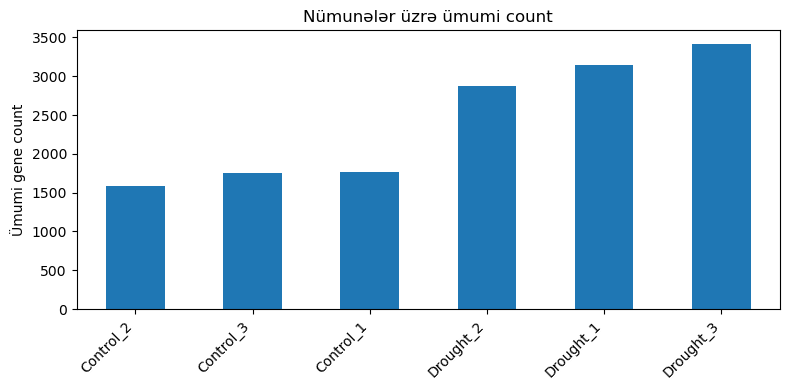

In [6]:
sample_totals = counts.sum(axis=0).sort_values()

plt.figure(figsize=(8, 4))
sample_totals.plot(kind="bar")
plt.ylabel("Ümumi gene count")
plt.title("Nümunələr üzrə ümumi count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [7]:
counts.to_csv("count_matrix.csv")
metadata.to_csv("metadata.csv")

print("count_matrix.csv və metadata.csv faylları yaradıldı.")

count_matrix.csv və metadata.csv faylları yaradıldı.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

counts = pd.read_csv("count_matrix.csv", index_col=0)
metadata = pd.read_csv("metadata.csv", index_col=0)

display(counts.head())
display(metadata)

,Control_1,Control_2,Control_3,Drought_1,Drought_2,Drought_3
gene_id,,,,,,
RD29A,140,82,164,804,422,793
RD29B,61,94,127,463,310,432
NCED3,94,55,105,397,291,439
DREB2A,78,83,85,234,190,215
P5CS1,129,135,88,191,367,374


,condition
sample,
Control_1,control
Control_2,control
Control_3,control
Drought_1,drought
Drought_2,drought
Drought_3,drought


In [13]:
control_samples = metadata.index[metadata["condition"] == "control"]
drought_samples = metadata.index[metadata["condition"] == "drought"]

control = counts[control_samples]
drought = counts[drought_samples]

print("Kontrol nümunələrinin sayı:", control.shape[1])
print("Quraqlıq nümunələrinin sayı:", drought.shape[1])

Kontrol nümunələrinin sayı: 3
Quraqlıq nümunələrinin sayı: 3


In [14]:
control_mean = control.mean(axis=1)
drought_mean = drought.mean(axis=1)

results = pd.DataFrame({
    "control_mean": control_mean,
    "drought_mean": drought_mean
})

results["log2FoldChange"] = np.log2(
    (results["drought_mean"] + 1) /
    (results["control_mean"] + 1)
)

results = results.sort_values("log2FoldChange", ascending=False)

display(results)

,control_mean,drought_mean,log2FoldChange
gene_id,,,
RD29A,128.666667,673.000000,2.377941
NCED3,84.666667,375.666667,2.136483
RD29B,94.000000,401.666667,2.083587
P5CS1,117.333333,310.666667,1.397147
DREB2A,82.000000,213.000000,1.366428
UBQ10,146.000000,219.000000,0.581687
GENE14,70.666667,87.000000,0.296201
GENE12,91.666667,102.666667,0.161830
GENE11,85.666667,95.666667,0.157541


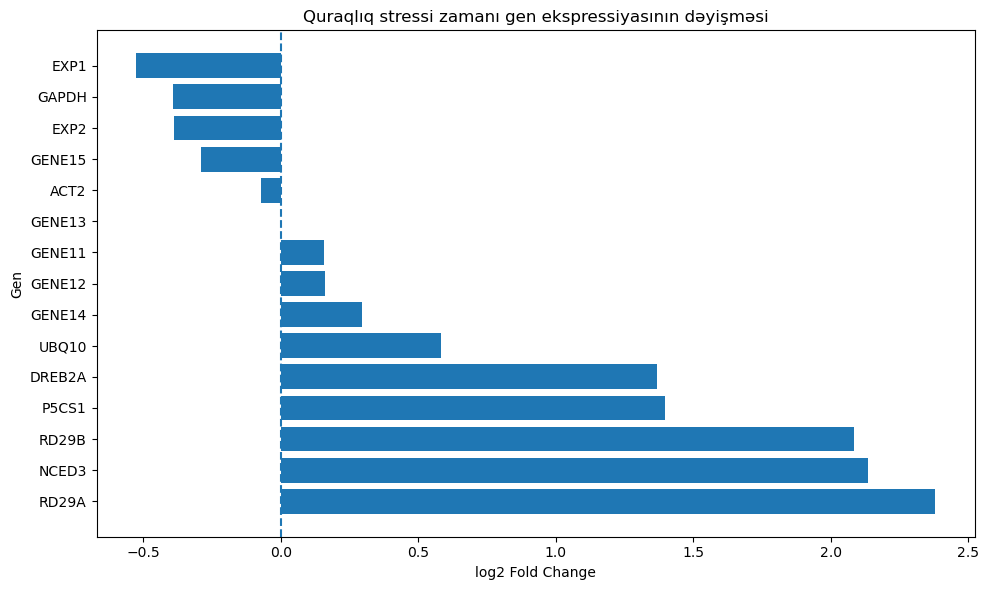

In [15]:
plt.figure(figsize=(10, 6))

plt.barh(results.index, results["log2FoldChange"])

plt.axvline(0, linestyle="--")
plt.xlabel("log2 Fold Change")
plt.ylabel("Gen")
plt.title("Quraqlıq stressi zamanı gen ekspressiyasının dəyişməsi")
plt.tight_layout()
plt.show()

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Faylları oxuyuruq
counts = pd.read_csv("count_matrix.csv", index_col=0)
metadata = pd.read_csv("metadata.csv", index_col=0)

# Nümunə və gen adlarını mətn formatına salırıq
counts.index = counts.index.astype(str)
counts.columns = counts.columns.astype(str)
metadata.index = metadata.index.astype(str)

# Count dəyərlərini ədədi formata çeviririk
counts = counts.apply(pd.to_numeric, errors="raise")

# Nümunə adlarının hər iki faylda olmasını yoxlayırıq
missing = counts.columns.difference(metadata.index)

if len(missing) > 0:
    raise ValueError(f"Metadata-da tapılmayan nümunələr: {list(missing)}")

# Metadata sırasını count matrisinə uyğunlaşdırırıq
metadata = metadata.loc[counts.columns].copy()

# Əsas yoxlamalar
if counts.isna().any().any():
    raise ValueError("Count matrisində boş dəyərlər var.")

if (counts < 0).any().any():
    raise ValueError("Count dəyərləri mənfi ola bilməz.")

if not np.allclose(counts.to_numpy(), np.round(counts.to_numpy())):
    raise ValueError("RNA-seq count məlumatları tam ədədlər olmalıdır.")

if "condition" not in metadata.columns:
    raise ValueError("Metadata-da condition sütunu yoxdur.")

print("Gen sayı:", counts.shape[0])
print("Nümunə sayı:", counts.shape[1])
print("\nQruplar üzrə nümunə sayı:")
print(metadata["condition"].value_counts())

display(counts.head())
display(metadata)

Gen sayı: 15
Nümunə sayı: 6

Qruplar üzrə nümunə sayı:
condition
control    3
drought    3
Name: count, dtype: int64


,Control_1,Control_2,Control_3,Drought_1,Drought_2,Drought_3
gene_id,,,,,,
RD29A,140,82,164,804,422,793
RD29B,61,94,127,463,310,432
NCED3,94,55,105,397,291,439
DREB2A,78,83,85,234,190,215
P5CS1,129,135,88,191,367,374


,condition
Control_1,control
Control_2,control
Control_3,control
Drought_1,drought
Drought_2,drought
Drought_3,drought


,Sample,Condition,Total_counts,Detected_genes
0,Control_1,control,1770,15
1,Control_2,control,1589,15
2,Control_3,control,1759,15
3,Drought_1,drought,3145,15
4,Drought_2,drought,2879,15
5,Drought_3,drought,3421,15


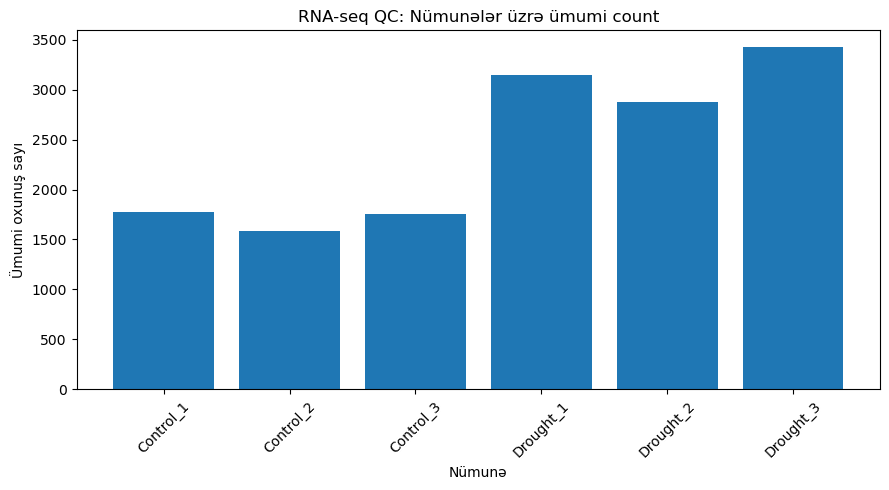

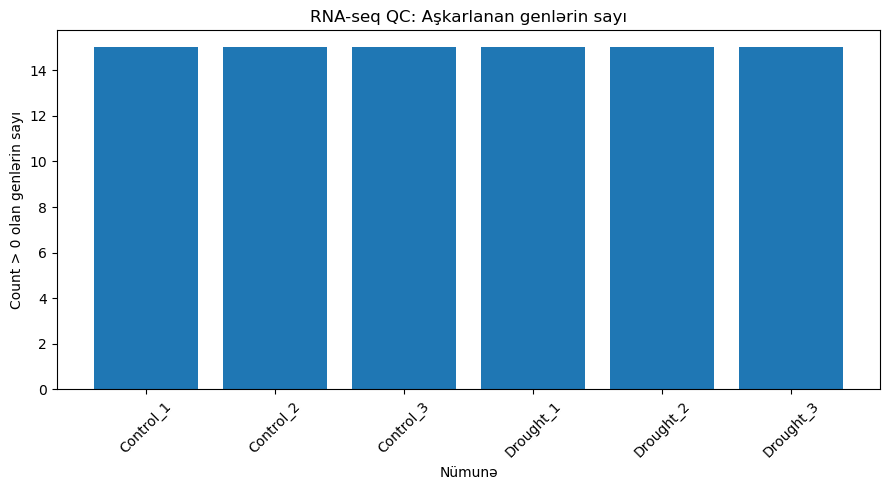

In [17]:
# Hər nümunənin ümumi count sayı
library_size = counts.sum(axis=0)

# Hər nümunədə ən azı bir oxunuş olan genlərin sayı
detected_genes = (counts > 0).sum(axis=0)

qc = pd.DataFrame({
    "Sample": counts.columns,
    "Condition": metadata["condition"].values,
    "Total_counts": library_size.values,
    "Detected_genes": detected_genes.values
})

display(qc)

# Ümumi oxunuş sayı
plt.figure(figsize=(9, 5))
plt.bar(qc["Sample"], qc["Total_counts"])
plt.ylabel("Ümumi oxunuş sayı")
plt.xlabel("Nümunə")
plt.title("RNA-seq QC: Nümunələr üzrə ümumi count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Aşkarlanan gen sayı
plt.figure(figsize=(9, 5))
plt.bar(qc["Sample"], qc["Detected_genes"])
plt.ylabel("Count > 0 olan genlərin sayı")
plt.xlabel("Nümunə")
plt.title("RNA-seq QC: Aşkarlanan genlərin sayı")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Filtrasiyadan əvvəl gen sayı: 15
Filtrasiyadan sonra gen sayı: 15
Çıxarılan gen sayı: 0


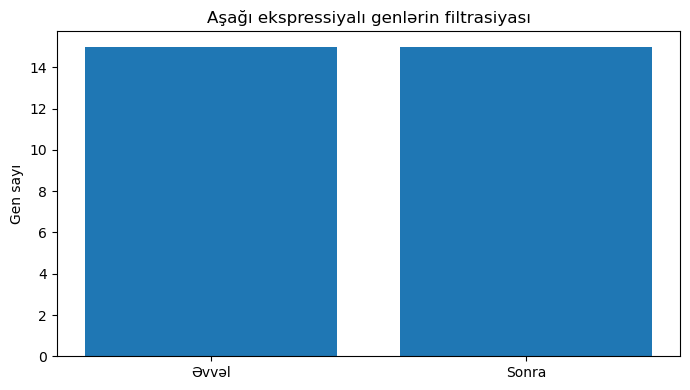

In [18]:
# Genin ən azı iki nümunədə count >= 10 olması tələb edilir
keep = (counts >= 10).sum(axis=1) >= 2

filtered_counts = counts.loc[keep].copy()

print("Filtrasiyadan əvvəl gen sayı:", counts.shape[0])
print("Filtrasiyadan sonra gen sayı:", filtered_counts.shape[0])
print("Çıxarılan gen sayı:", counts.shape[0] - filtered_counts.shape[0])

# Filtrasiyadan əvvəl və sonra ümumi gen sayları
plt.figure(figsize=(7, 4))
plt.bar(
    ["Əvvəl", "Sonra"],
    [counts.shape[0], filtered_counts.shape[0]]
)
plt.ylabel("Gen sayı")
plt.title("Aşağı ekspressiyalı genlərin filtrasiyası")
plt.tight_layout()
plt.show()

In [19]:
# Hər nümunənin ümumi count sayı
library_size = filtered_counts.sum(axis=0)

# Sıfır ümumi count olan nümunə varsa, analiz dayandırılır
if (library_size == 0).any():
    raise ValueError("Ümumi count sayı sıfır olan nümunə var.")

# CPM normallaşdırması
cpm = filtered_counts.div(library_size, axis=1) * 1_000_000

# Log2 çevrilməsi: sıfır dəyərləri üçün pseudocount = 1
log2_cpm = np.log2(cpm + 1)

print("CPM matrisi:")
display(cpm.head())

print("Log2-CPM matrisi:")
display(log2_cpm.head())

CPM matrisi:


,Control_1,Control_2,Control_3,Drought_1,Drought_2,Drought_3
gene_id,,,,,,
RD29A,79096.045198,51604.782882,93234.792496,255643.879173,146578.673150,231803.566209
RD29B,34463.276836,59156.702329,72200.113701,147217.806041,107676.276485,126278.865829
NCED3,53107.344633,34612.964128,59693.007391,126232.114467,101076.762765,128325.051155
DREB2A,44067.796610,52234.109503,48322.910745,74403.815580,65995.137200,62847.120725
P5CS1,72881.355932,84959.093770,50028.425242,60731.319555,127474.817645,109324.758842


Log2-CPM matrisi:


,Control_1,Control_2,Control_3,Drought_1,Drought_2,Drought_3
gene_id,,,,,,
RD29A,16.271336,15.655245,16.508596,17.963782,17.161326,17.822549
RD29B,15.072814,15.852278,16.139733,17.167602,16.716354,16.946265
NCED3,15.696651,15.079067,15.865298,16.945731,16.625106,16.969455
DREB2A,15.427470,15.672732,15.560450,16.183108,16.010094,15.939582
P5CS1,16.153282,16.374498,15.610489,15.890177,16.959864,16.738274


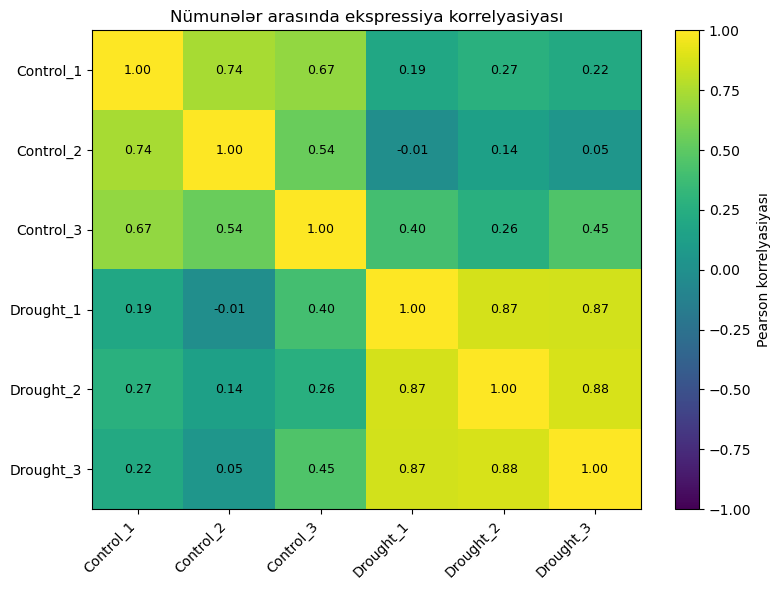

In [22]:
correlation = log2_cpm.corr(method="pearson")

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(correlation, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(correlation.columns)))
ax.set_xticklabels(correlation.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlation.index)))
ax.set_yticklabels(correlation.index)

for i in range(len(correlation)):
    for j in range(len(correlation)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=9)

fig.colorbar(im, ax=ax, label="Pearson korrelyasiyası")
ax.set_title("Nümunələr arasında ekspressiya korrelyasiyası")
plt.tight_layout()
plt.show()

PC1 izah etdiyi variasiya: 72.29%
PC2 izah etdiyi variasiya: 10.72%


,PC1,PC2,condition
Control_1,3.248243,0.153441,control
Control_2,3.540201,-0.888895,control
Control_3,2.801784,1.586138,control
Drought_1,-4.178614,1.273267,drought
Drought_2,-1.701072,-2.167776,drought
Drought_3,-3.710542,0.043825,drought


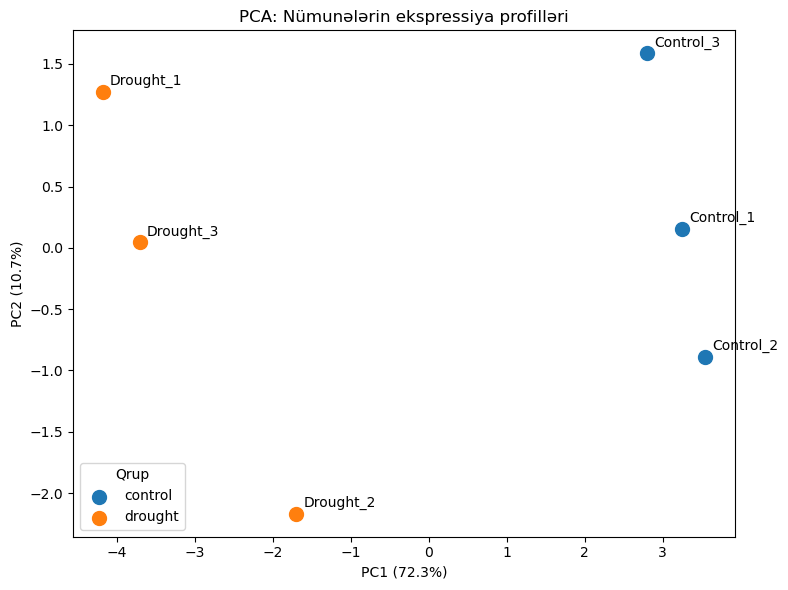

In [23]:
# Sətirlər nümunələr, sütunlar genlərdir
X = log2_cpm.T.copy()

# Hər gen üzrə orta qiyməti çıxırıq
X_centered = X - X.mean(axis=0)

# Genlərin standart kənarlaşması ilə miqyaslandırılması
gene_sd = X_centered.std(axis=0, ddof=0)
gene_sd[gene_sd == 0] = 1

X_scaled = X_centered / gene_sd

# SVD vasitəsilə PCA
U, singular_values, Vt = np.linalg.svd(
    X_scaled.to_numpy(),
    full_matrices=False
)

# Əsas komponentlər üzrə koordinatlar
scores = U * singular_values

# İzah edilən variasiya payı
variance = singular_values ** 2
explained = variance / variance.sum() * 100

pca = pd.DataFrame(
    scores[:, :2],
    index=X.index,
    columns=["PC1", "PC2"]
)

pca["condition"] = metadata.loc[pca.index, "condition"]

print(f"PC1 izah etdiyi variasiya: {explained[0]:.2f}%")
print(f"PC2 izah etdiyi variasiya: {explained[1]:.2f}%")

display(pca)

plt.figure(figsize=(8, 6))

for group in pca["condition"].unique():
    subset = pca[pca["condition"] == group]
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        s=100,
        label=group
    )

    for sample, row in subset.iterrows():
        plt.annotate(
            sample,
            (row["PC1"], row["PC2"]),
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.xlabel(f"PC1 ({explained[0]:.1f}%)")
plt.ylabel(f"PC2 ({explained[1]:.1f}%)")
plt.title("PCA: Nümunələrin ekspressiya profilləri")
plt.legend(title="Qrup")
plt.tight_layout()
plt.show()